In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/heart_missining.csv')
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125.0,212,0,NaN,168.0,0,1.0,2,2.0,3.0,0
1,53,1,0,140.0,203,1,0.0,155.0,1,3.1,0,0.0,3.0,0
2,70,1,0,145.0,174,0,1.0,125.0,1,2.6,0,0.0,3.0,0
3,61,1,0,148.0,203,0,1.0,NaN,0,0.0,2,1.0,3.0,0
4,62,0,0,138.0,294,1,1.0,106.0,0,1.9,1,3.0,2.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140.0,221,0,1.0,164.0,1,0.0,2,0.0,2.0,1
1021,60,1,0,125.0,258,0,0.0,141.0,1,2.8,1,1.0,3.0,0
1022,47,1,0,110.0,275,0,0.0,118.0,1,1.0,1,1.0,2.0,0
1023,50,0,0,110.0,254,0,0.0,159.0,0,0.0,2,0.0,2.0,1


In [ ]:
df.shape

(1025, 14)

In [ ]:
df.dtypes

,0
age,int64
sex,int64
cp,int64
trestbps,float64
chol,int64
fbs,int64
restecg,float64
thalach,float64
exang,int64
oldpeak,float64


In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1024.000000,1025.00000,1025.000000,1024.000000,1024.000000,1025.000000,1025.000000,1025.000000,1023.000000,1024.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.603516,246.00000,0.149268,0.529297,149.102539,0.336585,1.071512,1.385366,0.752688,2.324219,0.513171
std,9.072290,0.460373,1.029641,17.523313,51.59251,0.356527,0.527931,23.013962,0.472772,1.175053,0.617755,1.029140,0.620881,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,1
chol,0
fbs,0
restecg,1
thalach,1
exang,0
oldpeak,0


In [ ]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [ ]:
df['trestbps'].unique()

array([125., 140., 145., 148., 138., 100., 114., 160., 120., 122., 112.,
       132., 118., 128.,  nan, 124., 106., 104., 135., 130., 136., 180.,
       129., 150., 178., 146., 117., 152., 154., 170., 134., 174., 144.,
       108., 123., 110., 142., 126., 192., 115.,  94., 200., 165., 102.,
       105., 155., 172., 164., 156., 101.])

In [ ]:
df['restecg'].unique()

array([nan,  0.,  1.,  2.])

In [ ]:
df['thalach'].unique()

array([168., 155., 125.,  nan, 106., 122., 140., 145., 144., 116., 136.,
       192., 156., 142., 109., 162., 165., 148., 172., 173., 146., 179.,
       152., 117., 115., 112., 163., 147., 182., 105., 150., 151., 169.,
       166., 178., 132., 160., 123., 139., 111., 180., 164., 202., 157.,
       159., 170., 138., 175., 158., 126., 143., 141., 167.,  95., 190.,
       118., 103., 181., 108., 177., 134., 120., 171., 149., 154., 153.,
        88., 174., 114., 195., 133.,  96., 124., 131., 185., 194., 128.,
       127., 186., 184., 188., 130.,  71., 161., 137.,  99., 121., 187.,
        97.,  90., 129., 113.])

In [ ]:
df['ca'].unique()

array([ 2.,  0.,  1.,  3., nan,  4.])

In [ ]:
df['thal'].unique()

array([ 3.,  2.,  1.,  0., nan])

In [ ]:
df['trestbps'] = df['trestbps'].fillna(df['trestbps'].mode()[0])

df['restecg'] = df['restecg'].fillna(df['restecg'].mode()[0])

df['thalach'] = df['thalach'].fillna(df['thalach'].mean())

df['ca'] = df['ca'].fillna(df['ca'].mode()[0])

df['thal'] = df['thal'].fillna(df['thal'].mode()[0])

In [ ]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
df.duplicated().sum()

np.int64(720)

In [ ]:
a = df.corr(numeric_only=True)
a

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.103240,-0.071966,0.271516,0.219823,0.121243,-0.132696,-0.390644,0.088163,0.208137,-0.169105,0.270992,0.072297,-0.229324
sex,-0.103240,1.000000,-0.041119,-0.077281,-0.198258,0.027200,-0.055117,-0.049706,0.139157,0.084687,-0.026666,0.110077,0.198424,-0.279501
cp,-0.071966,-0.041119,1.000000,0.037028,-0.081641,0.079294,0.043581,0.307342,-0.401513,-0.174733,0.131633,-0.173964,-0.163341,0.434854
trestbps,0.271516,-0.077281,0.037028,1.000000,0.126625,0.182215,-0.122663,-0.039393,0.061984,0.187008,-0.121542,0.107353,0.059852,-0.139843
chol,0.219823,-0.198258,-0.081641,0.126625,1.000000,0.026917,-0.147410,-0.021354,0.067382,0.064880,-0.014248,0.070438,0.100244,-0.099966
fbs,0.121243,0.027200,0.079294,0.182215,0.026917,1.000000,-0.104051,-0.008656,0.049261,0.010859,-0.061902,0.138632,-0.042177,-0.041164
restecg,-0.132696,-0.055117,0.043581,-0.122663,-0.147410,-0.104051,1.000000,0.047967,-0.065606,-0.050114,0.086086,-0.086166,-0.020504,0.134468
thalach,-0.390644,-0.049706,0.307342,-0.039393,-0.021354,-0.008656,0.047967,1.000000,-0.379971,-0.349381,0.394857,-0.207339,-0.098631,0.423469
exang,0.088163,0.139157,-0.401513,0.061984,0.067382,0.049261,-0.065606,-0.379971,1.000000,0.310844,-0.267335,0.110099,0.197201,-0.438029
oldpeak,0.208137,0.084687,-0.174733,0.187008,0.064880,0.010859,-0.050114,-0.349381,0.310844,1.000000,-0.575189,0.214207,0.202672,-0.438441


<Axes: >

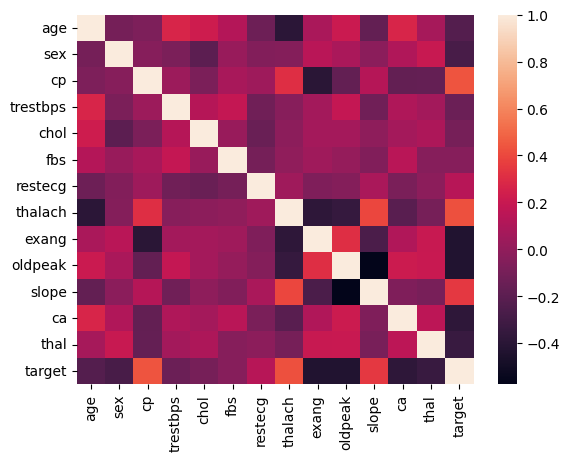

In [ ]:
sns.heatmap(a)

In [ ]:
x = df.drop(columns='target')
x.ndim
x

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125.0,212,0,1.0,168.000000,0,1.0,2,2.0,3.0
1,53,1,0,140.0,203,1,0.0,155.000000,1,3.1,0,0.0,3.0
2,70,1,0,145.0,174,0,1.0,125.000000,1,2.6,0,0.0,3.0
3,61,1,0,148.0,203,0,1.0,149.102539,0,0.0,2,1.0,3.0
4,62,0,0,138.0,294,1,1.0,106.000000,0,1.9,1,3.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140.0,221,0,1.0,164.000000,1,0.0,2,0.0,2.0
1021,60,1,0,125.0,258,0,0.0,141.000000,1,2.8,1,1.0,3.0
1022,47,1,0,110.0,275,0,0.0,118.000000,1,1.0,1,1.0,2.0
1023,50,0,0,110.0,254,0,0.0,159.000000,0,0.0,2,0.0,2.0


In [ ]:
y = df['target']
y.ndim
y

,target
0,0
1,0
2,0
3,0
4,0
...,...
1020,1
1021,0
1022,0
1023,1


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20, random_state=1)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=9)
knn.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=9)

In [ ]:
y_pred = knn.predict(x_test)
y_pred

array([0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1,
       0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 0, 1, 0])

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
cm = confusion_matrix(y_test, y_pred)
cm

array([[88, 21],
       [ 8, 88]])

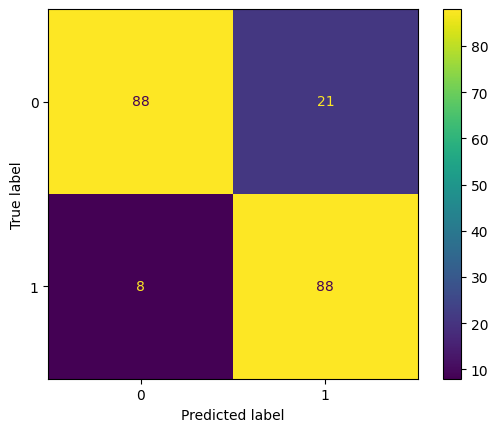

In [ ]:
cmd = ConfusionMatrixDisplay(cm)
cmd.plot()

In [ ]:
score = accuracy_score(y_test, y_pred)
score

0.8585365853658536